# Import all packages

In [1]:
using DifferentialEquations
using OrdinaryDiffEq
using DiffEqBase
using Sundials
using ODEInterfaceDiffEq
using Plots
using Measures
using CSV
using DataFrames
using EasyFit
using StatsPlots
using LinearAlgebra
using Random
using Distributions
using OrdinaryDiffEq
Random.seed!(145975);
using CmdStan
using KernelDensity
using LaTeXStrings
using StatsBase
using JLD2
using BlackBoxOptim
using BlackBoxOptim: num_func_evals
using HypothesisTests
using BayesianOptimization, GaussianProcesses

set_cmdstan_home!("C:\\cmdstan\\cmdstan-2.30.0");

┌ Warning: Environment variable CMDSTAN_HOME not set. Use set_cmdstan_home!.
└ @ CmdStan C:\Users\dgomez\.julia\packages\CmdStan\2vwWj\src\CmdStan.jl:27


In [2]:
# include("D:\\David\\BayesianInferencesInVivoScripts\\FunctionsBayesInfs.jl")
# include("D:\\David\\BayesianInferencesInVivoScripts\\ModelFunctionsAll.jl")
# include("D:\\David\\BayesianInferencesInVivoScripts\\FunctionsBayesOED.jl")

include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\BayesianInference\\FunctionsBayesInfs.jl")
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\InitalParameterFitPriorDef\\ModelFunctionsAll.jl")
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ComputationalBayesianOED\\FunctionsBayesOED.jl")

redSamples (generic function with 2 methods)

# Define Original Priors

In [3]:
NSamps = 8000;

priorTheta = Array{Any}(undef, 13);
priotY0 = Array{Any}(undef, 3);

priorTheta[1] = Normal(40.92, 10); priorTheta[2] = Normal(51.23, 10); priorTheta[3] = Truncated(Normal(0.0055, 0.0055), 0,2); priorTheta[4] = Truncated(Normal(0.0275, 0.0275), 0,2); 
priorTheta[5] = Truncated(Normal(0.045, 0.045), 0,2); priorTheta[6] = Truncated(Normal(0.45, 0.45), 0,2); priorTheta[7] = Truncated(Normal(0.95, 0.95), 0,2); 
priorTheta[8] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[9] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[10] = Truncated(Normal(0.0085, 0.0085), 0,2);
priorTheta[11] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[12] = Truncated(Normal(0.0029, 0.0029), 0,2); priorTheta[13] = Normal(18.5, 2.29);

priotY0[1] = Truncated(Normal(650, 260), 0, 1600); priotY0[2] = Truncated(Normal(16000, 6400), 0, 4e4); priotY0[3] = Truncated(Normal(550, 275), 0, 1600);

global sampsTh = zeros(NSamps, 13);
global sampsY0 = zeros(NSamps, 3);

Random.seed!(687865443); 

for i in 1:13
    sampsTh[:,i] = rand(priorTheta[i], NSamps);
end
for i in 1:3
    sampsY0[:,i] = rand(priotY0[i], NSamps);
end

sampsTh[:,2] .= 51.23; # T1 of Pyruvate is fixed since it is irrelevant for the model for the problem and can be estimated with experiments without cells. 
sampsTh[:,13] .= 15; # This will be re-writen with the empirical value once extracted from data

In [4]:
bounds = [zeros(12), zeros(12)];
boundY0 = [[0, 0, 0], [1600, 4e4, 1600]];
for i in 1:12
    if i >= 3
        if priorTheta[i].untruncated.μ - (priorTheta[i].untruncated.σ*4) >= 0
            bounds[1][i] = priorTheta[i].untruncated.μ - (priorTheta[i].untruncated.σ*4);
        else
            bounds[1][i] = 0;
        end
        if priorTheta[i].untruncated.μ + (priorTheta[i].untruncated.σ*4) <= 2
            bounds[2][i] = priorTheta[i].untruncated.μ + (priorTheta[i].untruncated.σ*4);
        else
            bounds[2][i] = 2;
        end
    elseif i == 1
        bounds[1][i] = priorTheta[i].μ - (priorTheta[i].σ*4);
        bounds[2][i] = priorTheta[i].μ + (priorTheta[i].σ*4);
    elseif i == 2
        bounds[1][i] = 51.23;
        bounds[2][i] = 51.23;
    end
end

In [5]:
priorInfer =  Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\Results\\PosteriorCompetitiveRepressionExp_ID1_Try1.csv", DataFrame))

8000×16 Matrix{Float64}:
 44.2699  51.23  0.00349537  0.0208736  …   79.1747  11677.9    482.294
 40.9763  51.23  0.00432778  0.0187617     100.675   14284.0    437.361
 44.5524  51.23  0.00857555  0.0203628     182.498   17415.4    804.075
 48.9419  51.23  0.00450079  0.0231909     112.442    7958.43   597.776
 45.039   51.23  0.0055969   0.0205603     387.912   14161.5    584.065
 48.2531  51.23  0.00562478  0.0249253  …  632.128   14909.5    475.244
 47.8301  51.23  0.0110417   0.0229498     624.252   16898.1    456.397
 40.6544  51.23  0.00654779  0.019724      812.556   14135.5    675.263
 43.0763  51.23  0.015096    0.0215315     345.361   22247.8    313.601
 44.4862  51.23  0.00821166  0.0226195     359.008   24794.4    333.7
  ⋮                                     ⋱                         ⋮
 47.0656  51.23  0.00448371  0.0233377      75.1879  26870.1    862.848
 43.1541  51.23  0.00578506  0.0201927      97.8729  23337.6    817.492
 52.3638  51.23  0.00432448  0.0279674      7

# Intuition Driven Experimental Design (ID)

## Generate Repression Curve with Prior Means to Identify "Good" Sampling Point
Will do this for each posterior to assess better the sampling. At this iteration, we will choose the double of the previous concentration used since it is a common practice in the HP-NMR community and is more or less 3 equidistant points. 

In [6]:
tsC2 = vcat(0, collect(15:5:395));
ts = 0:tsC2[end];
samps = convert.(Int, tsC2);

In [7]:
Pyrs = collect(0:0.1:40);

Sims = Array{Any}(undef, length(Pyrs));

for i in 1:length(Pyrs)
    ivss = [Pyrs[i].*1000, 0, 0, mean(priorInfer[:,14], dims=1)[1], mean(priorInfer[:,15], dims=1)[1], mean(priorInfer[:,16], dims=1)[1], 0, 0, 0, 0, 0, Pyrs[i].*1000, 0, Pyrs[i].*1000*(priorInfer[1,13]*0.12)];
    
    SimulsAll1, SimulsAll2, SimulsAll3  = PyruvateHP_NMR_SolveAllCp(ts, hcat(mean(priorInfer[:,1:13], dims=1), 0), ivss, samps);
    Sims[i] = SimulsAll1;
end


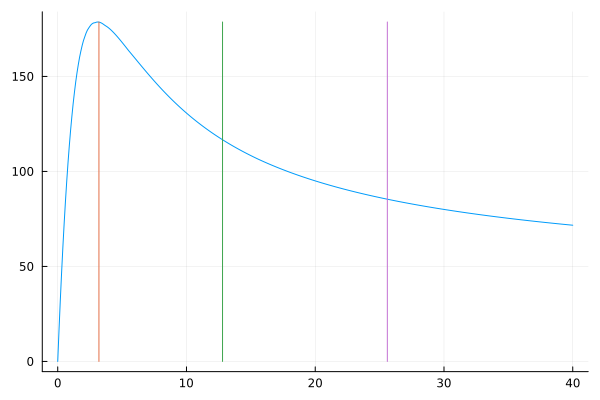

In [8]:
# If we consider for the curve the maximum value on the lactate curve
Lacs = zeros(length(Pyrs));

for i in 1:length(Pyrs)
    Lacs[i] = maximum(Sims[i][:,13,1]);
end

plot(Pyrs, Lacs, label = "")
plot!([3.2, 3.2],[0, maximum(Lacs)], label = "")
plot!([12.8, 12.8],[0, maximum(Lacs)], label = "")
plot!([25.6, 25.6],[0, maximum(Lacs)], label = "")

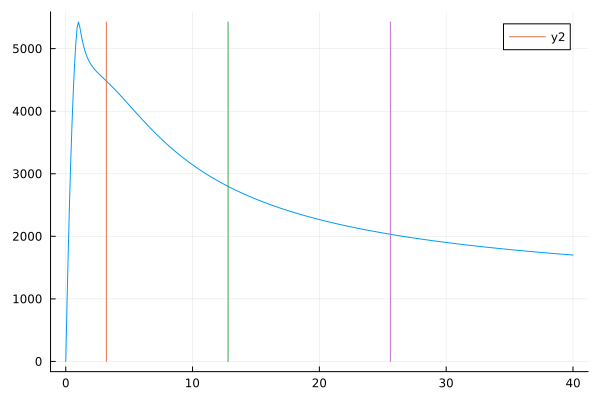

In [9]:
# If we consider for the curve the sum of all data points of the lactate curve

Lacs = zeros(length(Pyrs));

for i in 1:length(Pyrs)
    Lacs[i] = sum(Sims[i][:,13,1]);
end

plot(Pyrs, Lacs, label = "")
plot!([3.2, 3.2],[0, maximum(Lacs)])
plot!([12.8, 12.8],[0, maximum(Lacs)], label = "")
plot!([25.6, 25.6],[0, maximum(Lacs)], label = "")

In [10]:
PyrCons = [25.6]

1-element Vector{Float64}:
 25.6

In [11]:
global tsC2 = vcat(0, collect(15:5:395));
global ts = 0:tsC2[end];
global samps = convert.(Int, tsC2);

global sampsTh = priorInfer[:,1:13];
global sampsY0 = priorInfer[:,14:end];
CompRepUtil_Entro_OEDmc(PyrCons)

72.35064718442467

## Simulate Experiment Prio Prediction

In [13]:
simsPrior = Array{Any}(undef, 8000);

tsC2 = vcat(0, collect(15:5:395));
for i in 1:8000
    ts = 0:tsC2[end];
    ivss = [round(PyrCons[1], digits = 1)*1000, 0, 0, priorInfer[i,14], priorInfer[i,15], priorInfer[i,16], 0, 0, 0, 0, 0, round(PyrCons[1], digits = 1)*1000, 0, round(PyrCons[1], digits = 1)*1000*(priorInfer[1,13]*0.12)];;
    samps = convert.(Int, tsC2);

    SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(priorInfer[i,1:13], 0), ivss, samps);
    simsPrior[i] = SimulsAll;
end

In [14]:
# Dims = Up/Down, Observable, Experiment
PriorQuant = Array{Any}(undef,2,1,1);
lacPirorSims = zeros(size(simsPrior[1])[1], 8000)
[lacPirorSims[:,i] = simsPrior[i][:,13,1] for i in 1:8000 ];
for k in 1:1
    for m in 1:1
        PriorQuant[1,k,m] = [percentile(lacPirorSims[j,:], 99.5) for j in 1:size(lacPirorSims)[1]]; # Up
        PriorQuant[2,k,m] = [percentile(lacPirorSims[j,:], 0.5 ) for j in 1:size(lacPirorSims)[1]]; # Down
    end
end

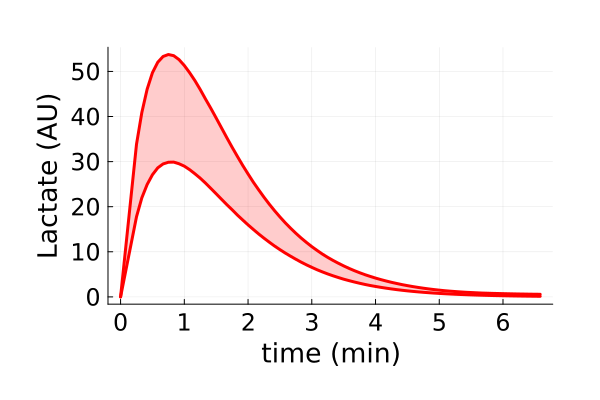

In [15]:
pr = plot(tsC2./60, PriorQuant[1], label = "", color = "red", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Lactate (AU)")
  plot!(tsC2./60, PriorQuant[2], label = "", color = "red", linewidth = 3)
  plot!(tsC2./60, PriorQuant[1], fillrange=PriorQuant[2], label="", color="red", fillalpha=0.2)

# .................................................... PERFORM EXPERIMENT ....................................................

80 uL of pyruvate + 170 uL of media from the 80 mM solution

# Extract Experimental Data 3.2 mM, 12.8 mM and 25.6 mM

In [24]:
mainpath = "D:\\David\\BayesianInferencesInVivoScripts\\ProcessedData\\";
i = 1;
paths = [mainpath*"3Mil_3-2mMPyr_Dat.csv", mainpath*"3Mil_12-8mMPyr_Dat.csv", mainpath*"3Mil_25-6mMPyr_Dat.csv"];
conce = [3.2, 12.8, 25.6];

In [25]:
Random.seed!(8987654);
global dat = restructDatInfCompRep_RealExpDat(paths, conce, rand(priotY0[i], 1)[1], rand(priotY0[i], 1)[1], rand(priotY0[i], 1)[1])

Dict{String, Any} with 15 entries:
  "Means"  => [9177.49 32574.2 81509.6; 6162.55 23317.9 57850.7; … ; -6.00262 4…
  "stsl"   => [77 77 77]
  "obSta"  => [1 2]
  "sts"    => [0 0 0; 20 20 20; … ; 390 390 390; 395 395 395]
  "obser"  => 2
  "Y0us"   => [3200.0 12800.0 25600.0; 0.0 0.0 0.0; … ; 0.0 0.0 0.0; 9177.49 32…
  "ts"     => [1.0e-20 1.0e-20 1.0e-20; 1.0 1.0 1.0; … ; 394.0 394.0 394.0; 395…
  "itp"    => [0.0, 0.0, 0.0]
  "ScFms"  => [23.8997 21.2072 26.5331]
  "ncells" => [4 4 4]
  "stslm"  => 77
  "tml"    => 396
  "Erros"  => [821.947 1846.98 3958.84; 491.932 1039.87 2750.92; … ; 7.38584 7.…
  "m"      => 3
  "nts"    => [395 395 395]

# Simulate Experiment Prior Prediction

In [26]:
simsPrior = Array{Any}(undef, 8000);
sampsTh[:,13] .= dat["ScFms"][end];

tsC2 = dat["sts"];
for i in 1:8000
    tsC2 = dat["sts"][:,end];
    ts = 0:tsC2[end];
    ivss = [round(conce[end], digits = 1)*1000, 0, 0, priorInfer[i,14], priorInfer[i,15], priorInfer[i,16], 0, 0, 0, 0, 0, round(conce[end], digits = 1)*1000, 0, round(conce[end], digits = 1)*1000*(dat["ScFms"][end]*0.12)];;
    samps = convert.(Int, tsC2);

    SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(priorInfer[i,1:13], 0), ivss, samps);

    simsPrior[i] = SimulsAll;
end

In [27]:
# Dims = Up/Down, Observable, Experiment
PriorQuant = Array{Any}(undef,2,1,1);
lacPirorSims = zeros(size(simsPrior[1])[1], 8000)
[lacPirorSims[:,i] = simsPrior[i][:,13,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:1
        PriorQuant[1,k,m] = [percentile(lacPirorSims[j,:], 99.5) for j in 1:size(lacPirorSims)[1]]; # Up
        PriorQuant[2,k,m] = [percentile(lacPirorSims[j,:], 0.5 ) for j in 1:size(lacPirorSims)[1]]; # Down
    end
end


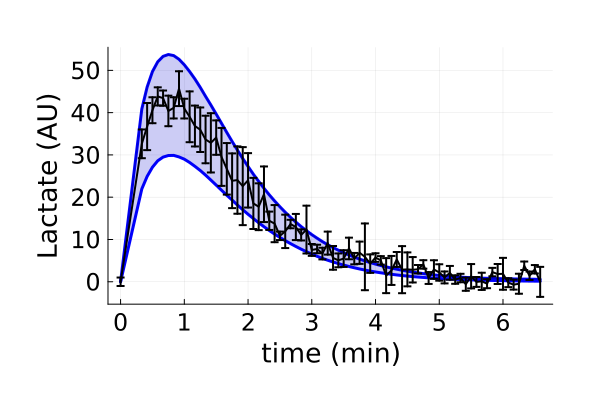

In [28]:
pr = plot(tsC2./60, PriorQuant[1], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Lactate (AU)")
  plot!(tsC2./60, PriorQuant[2], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PriorQuant[1], fillrange=PriorQuant[2], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,end]./60, dat["Means"][:,end,2], yerror = dat["Erros"][:,end,2], linewidth = 2, colour = "black", label = "")

# MLE to obtain a good first guess for inference

In [29]:
function ObjectFunctMECp_Multi_MLE(p)

    # Define parameter vectors for each amount of cells (last parameter is a time delay, not used in here)
    
    obj = 0;
    
    for i in 1:length(dat["stsl"])
        pD2 = vcat(p[1:end-3], dat["ScFms"][i], 0);

        # Define time vector
        t2cor = dat["sts"][:,i];

        # Define equaly-spaced time vector
        ts1 = collect(0:t2cor[end]);

        # Define initial value for simulation (use of experimental mean)
        ivss1 = [dat["Means"][1,i,1]/(dat["ScFms"][i]*0.12), 0, dat["Means"][1,i,2]/(dat["ScFms"][i]*0.12), p[end-2], p[end-1], p[end], 0, 0, 0, 0, 0, dat["Means"][1,i,1]/(dat["ScFms"][i]*0.12), dat["Means"][1,i,2], dat["Means"][1,i,1]];

        # Convert sampling vector to integer to extract correct elements from simulation
        samps1 = convert.(Int, t2cor);

        # Simulate
        SimOnTime1, SimOffTime1, SimAll1  = PyruvateHP_NMR_SolveAllCp(ts1, pD2, ivss1, samps1);
    
        # mm11 = sum((-1/2) .* (log(2*pi) .+ log.((dat["Erros"][:,i,1]/maximum(dat["Means"][:,i,1])).^2) .+ (((SimOnTime1[:,14]/maximum(dat["Means"][:,i,1])) .- 
        #                 (dat["Means"][:,i,1]/maximum(dat["Means"][:,i,1]))).^2)./((dat["Erros"][:,i,1]/maximum(dat["Means"][:,i,1])).^2)));
        mm11 = sum((-1/2) .* (log(2*pi) .+ log.(dat["Erros"][:,i,1].^2) .+ ((SimOnTime1[:,14] .- dat["Means"][:,i,1]).^2)./(dat["Erros"][:,i,1].^2)));
        mm22 = sum((-1/2) .* (log(2*pi) .+ log.(dat["Erros"][:,i,2].^2) .+ ((SimOnTime1[:,13] .- dat["Means"][:,i,2]).^2)./(dat["Erros"][:,i,2].^2)));
        # println(mm11)
        # obj = (mm21+mm22)*(mm11+mm12);
        if p[end-2] >= p[end-1]
            mm22 = mm22*10;
        end
        # obj = -(mm22)+obj;
        obj = -(mm22)+sqrt(abs(mm11))+obj;
    end
    
    return(obj)

end

ObjectFunctMECp_Multi_MLE (generic function with 1 method)

In [30]:
p = [48, 51.23, 0.044, 0.02, 0.02, 0.001, 0.01, 0.0003, 0.0001, 0.0002, 1e-1, 1e-6, 50/(15*0.12), 5000/(15*0.12), 700/(15*0.12)];
ObjectFunctMECp_Multi_MLE(p)

2698.8719792719744

In [31]:
Iters = 1;
CCsT = Array{Any}(undef,Iters);
FitsT = Array{Any}(undef,Iters);

i=1
fitness_progress_history = Array{Tuple{Int, Float64},1}()
callback = oc -> push!(fitness_progress_history, (num_func_evals(oc), best_fitness(oc)))

resM = bboptimize(ObjectFunctMECp_Multi_MLE; SearchRange = vcat([(bounds[1][i], bounds[2][i]) for i in 1:12], [(boundY0[1][i], boundY0[2][i]) for i in 1:3]), # T1_X, T1_P, kin, kpl, kf, kr, a1, a2, a3, b1, b2, b3
        MaxTime = 60*8, method = :adaptive_de_rand_1_bin, 
        CallbackFunction = callback, CallbackInterval = 0.0)

CCsT[i] = fitness_progress_history;
FitsT[i] = resM;

Starting optimization with optimizer DiffEvoOpt{FitPopulation{Float64}, RadiusLimitedSelector, BlackBoxOptim.AdaptiveDiffEvoRandBin{3}, RandomBound{ContinuousRectSearchSpace}}
0.00 secs, 0 evals, 0 steps
0.50 secs, 42 evals, 21 steps, improv/step: 0.333 (last = 0.3333), fitness=973.321257424
1.03 secs, 44 evals, 22 steps, improv/step: 0.364 (last = 1.0000), fitness=973.321257424
1.53 secs, 90 evals, 48 steps, improv/step: 0.438 (last = 0.5000), fitness=973.321257424
2.05 secs, 138 evals, 79 steps, improv/step: 0.405 (last = 0.3548), fitness=973.321257424
2.56 secs, 189 evals, 112 steps, improv/step: 0.384 (last = 0.3333), fitness=973.321257424
3.07 secs, 232 evals, 146 steps, improv/step: 0.370 (last = 0.3235), fitness=973.321257424
3.60 secs, 279 evals, 183 steps, improv/step: 0.366 (last = 0.3514), fitness=973.321257424
4.21 secs, 333 evals, 228 steps, improv/step: 0.338 (last = 0.2222), fitness=814.850372050
4.76 secs, 383 evals, 271 steps, improv/step: 0.317 (last = 0.2093), fitnes

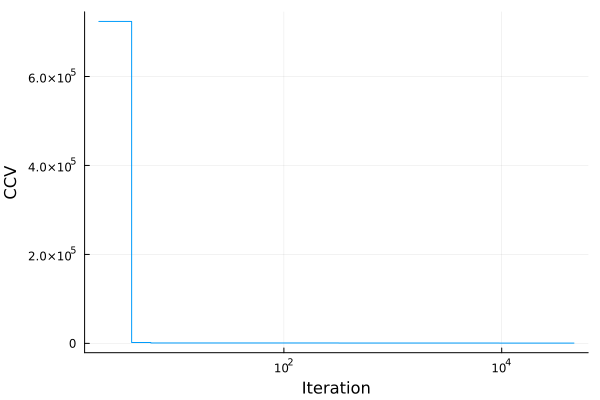

In [32]:
# Plot convergence curve
pl=plot(CCsT[1], xaxis=:log, linetype=:step, label = "", xlabel = "Iteration", ylabel = "CCV")
display(pl)

In [33]:
# Extract Parameter Vector
parfitT = zeros(15, Iters);
for i in 1:Iters
    parfitT[:,i] = best_candidate(FitsT[i]);
end
bestPind = findfirst([CCsT[i][end][2] for i in 1:length(CCsT)] .== minimum([CCsT[i][end][2] for i in 1:length(CCsT)]))
ppT = parfitT[:,bestPind]

15-element Vector{Float64}:
    43.97615724843133
    51.23
     0.02245128716752809
     0.023883554019207085
     0.06445974242636875
     0.21497746680944102
     1.815563916491423
     0.16530194384843921
     1.101525599969567
     0.04132368098077323
     0.06408438034193237
     0.001767751470712476
    77.15166629335502
 39022.80228039476
  1548.4244456888646

In [34]:
JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED\\MLEResults\\resMTRRCmp_Exper_ID2b.jld2", "FitsT",FitsT)
JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED\\MLEResults\\resMVectTRRCmp_Exper_ID2b.jld2", 
        "resMMat",parfitT, "CCsT", CCsT)

┌ Warning: Attempting to store var"#95#96".
│ JLD2 only stores functions by name.
│  This may not be useful for anonymous functions.
└ @ JLD2 C:\Users\dgomez\.julia\packages\JLD2\nPYlZ\src\data\writing_datatypes.jl:447
┌ Warning: Attempting to store BlackBoxOptim.var"#114#115".
│ JLD2 only stores functions by name.
│  This may not be useful for anonymous functions.
└ @ JLD2 C:\Users\dgomez\.julia\packages\JLD2\nPYlZ\src\data\writing_datatypes.jl:447


In [35]:
ppT = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED\\MLEResults\\resMVectTRRCmp_Exper_ID2b.jld2")["resMMat"][:,1]


15-element Vector{Float64}:
    43.97615724843133
    51.23
     0.02245128716752809
     0.023883554019207085
     0.06445974242636875
     0.21497746680944102
     1.815563916491423
     0.16530194384843921
     1.101525599969567
     0.04132368098077323
     0.06408438034193237
     0.001767751470712476
    77.15166629335502
 39022.80228039476
  1548.4244456888646

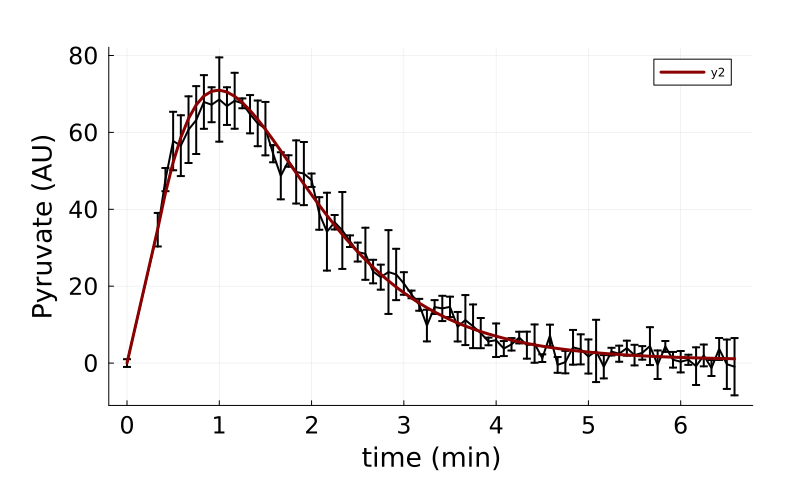

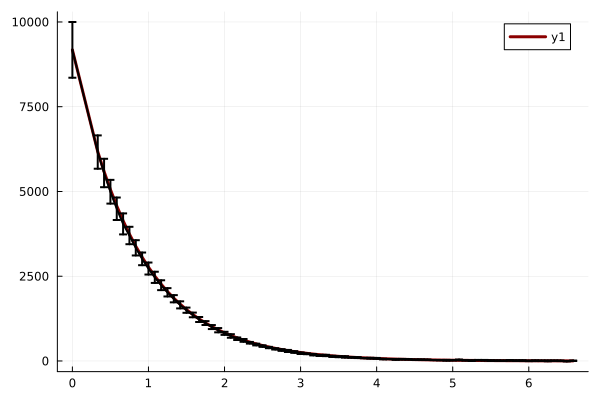

In [36]:
# Plot Simulation with best estimate against data
tsC2 = dat["sts"][:,1];
ts = 0:tsC2[end];
ivss = [round(conce[1], digits = 1)*1000, 0, 0, ppT[13], ppT[14], ppT[15], 0, 0, 0, 0, 0, round(conce[1], digits = 1)*1000, 0, round(conce[1], digits = 1)*1000*(dat["ScFms"][1]*0.12)];;
samps = convert.(Int, tsC2);

SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(ppT[1:12], dat["ScFms"][1], 0), ivss, samps);

pps = plot(dat["sts"][:,1]./60, dat["Means"][:,1,2], yerror = dat["Erros"][:,1,2], linewidth = 2, colour = "black", label = "",
            margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
            xlabel = "time (min)", ylabel = "Pyruvate (AU)", size = (800,500))

     plot!(tsC2./60, SimulsAll[:,13,1], linewidth=3, colour="red4")
display(pps)


ps = plot(tsC2./60, SimulsAll[:,14,1], linewidth=3, colour="red4")
plot!(dat["sts"][:,1]./60, dat["Means"][:,1,1], yerror = dat["Erros"][:,1,1], linewidth = 2, colour = "black", label = "")

display(ps)

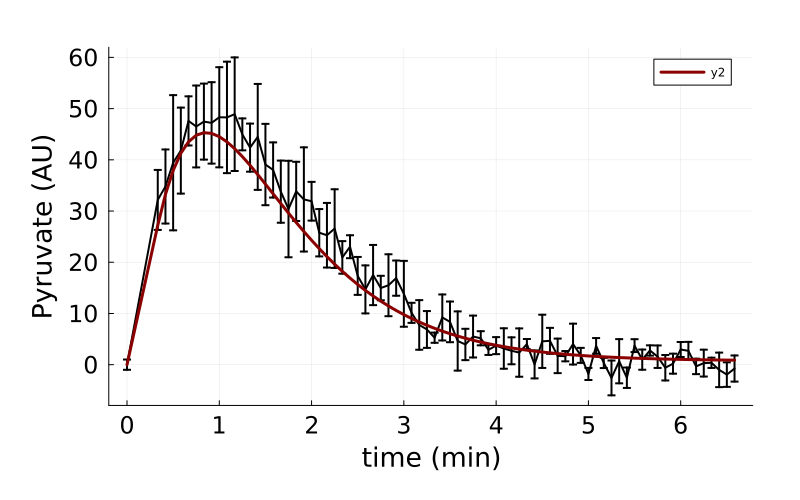

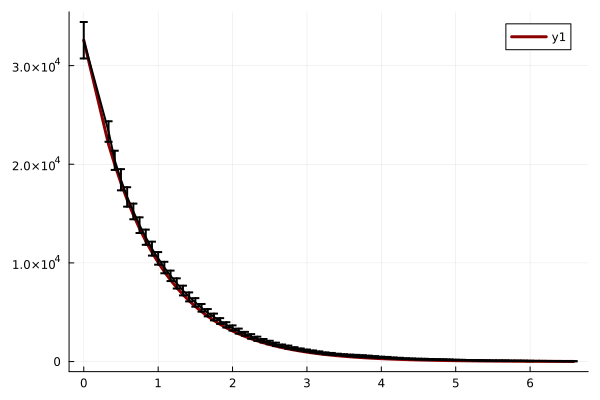

In [37]:
# Plot Simulation with best estimate against data
tsC2 = dat["sts"][:,2];
ts = 0:tsC2[end];
ivss = [round(conce[2], digits = 1)*1000, 0, 0, ppT[13], ppT[14], ppT[15], 0, 0, 0, 0, 0, round(conce[2], digits = 1)*1000, 0, round(conce[2], digits = 1)*1000*(dat["ScFms"][2]*0.12)];;
samps = convert.(Int, tsC2);

SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(ppT[1:12], dat["ScFms"][2], 0), ivss, samps);

pps = plot(dat["sts"][:,2]./60, dat["Means"][:,2,2], yerror = dat["Erros"][:,2,2], linewidth = 2, colour = "black", label = "",
            margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
            xlabel = "time (min)", ylabel = "Pyruvate (AU)", size = (800,500))

     plot!(tsC2./60, SimulsAll[:,13,1], linewidth=3, colour="red4")
display(pps)

ps = plot(tsC2./60, SimulsAll[:,14,1], linewidth=3, colour="red4")
plot!(dat["sts"][:,2]./60, dat["Means"][:,2,1], yerror = dat["Erros"][:,2,1], linewidth = 2, colour = "black", label = "")

display(ps)

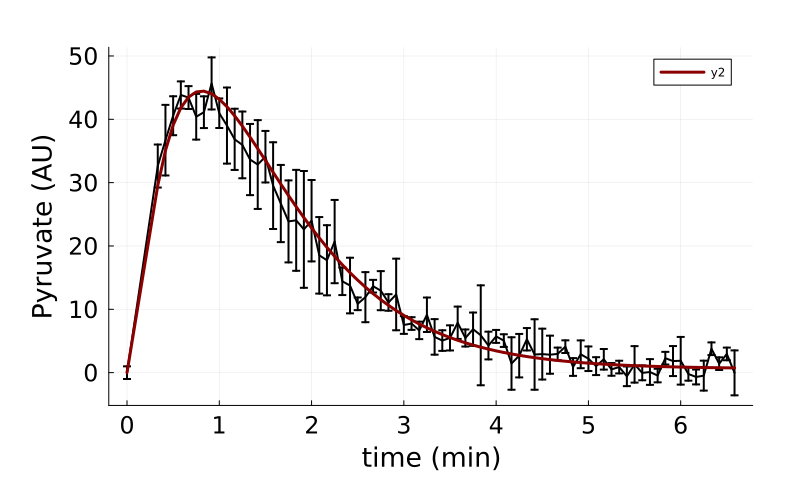

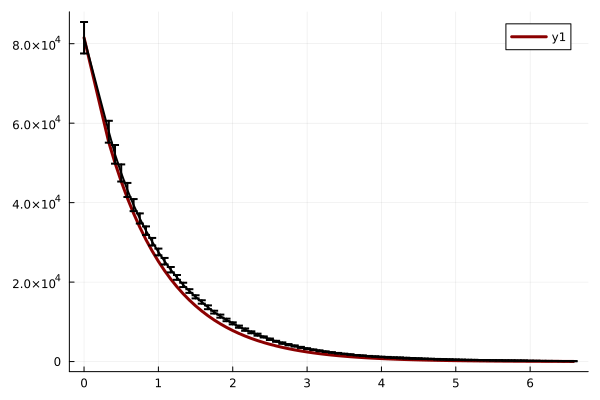

In [38]:
# Plot Simulation with best estimate against data
tsC2 = dat["sts"][:,end];
ts = 0:tsC2[end];
ivss = [round(conce[end], digits = 1)*1000, 0, 0, ppT[13], ppT[14], ppT[15], 0, 0, 0, 0, 0, round(conce[end], digits = 1)*1000, 0, round(conce[end], digits = 1)*1000*(dat["ScFms"][end]*0.12)];;
samps = convert.(Int, tsC2);

SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(ppT[1:12], dat["ScFms"][end], 0), ivss, samps);

pps = plot(dat["sts"][:,end]./60, dat["Means"][:,end,2], yerror = dat["Erros"][:,end,2], linewidth = 2, colour = "black", label = "",
            margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
            xlabel = "time (min)", ylabel = "Pyruvate (AU)", size = (800,500))

     plot!(tsC2./60, SimulsAll[:,13,1], linewidth=3, colour="red4")
display(pps)

ps = plot(tsC2./60, SimulsAll[:,14,1], linewidth=3, colour="red4")
plot!(dat["sts"][:,end]./60, dat["Means"][:,end,1], yerror = dat["Erros"][:,end,1], linewidth = 2, colour = "black", label = "")

display(ps)

## Compute structure for Stan's initial guess

In [39]:
preTrans = zeros(14);

preTrans[1] = (ppT[1]-40.92)/10; 
preTrans[2] = (ppT[3]-0.0055)/0.0055; 
preTrans[3] = (ppT[4]-0.0275)/0.0275;          
preTrans[4] = (ppT[5]-0.045)/0.045;
preTrans[5] = (ppT[6]-0.45)/0.45;
preTrans[6] = (ppT[7]-0.95)/0.95;
preTrans[7] = (ppT[8]-0.95)/0.95;
preTrans[8] = (ppT[9]-0.95)/0.95;
preTrans[9] = (ppT[10]-0.0085)/0.0085;
preTrans[10] = (ppT[11]-0.95)/0.95;
preTrans[11] = (ppT[12]-0.0029)/0.0029;


preTrans[12] = (ppT[13]-650)/260;
preTrans[13] = (ppT[14]-16000)/6400;
preTrans[14] = (ppT[15]-550)/275;

In [40]:

samps = hcat(preTrans,preTrans,preTrans,preTrans);
names = ["T1_X","kin","kpl","kbn","kun","kbp","kup","kunE","kbnE","ki","kr","NADH","NAD","LDH"];

ini = genStanInitDict(samps, names, 4)

4-element Vector{Dict{String, Any}}:
 Dict("kbnE" => 3.861609527149791, "LDH" => 3.6306343479595076, "kin" => 3.082052212277835, "ki" => -0.932542757534808, "kunE" => 0.15950063154691269, "kpl" => -0.1315071265742878, "NADH" => -2.2032628219486345, "kup" => -0.8259979538437482, "T1_X" => 0.3056157248431326, "kbp" => 0.9111199120962349…)
 Dict("kbnE" => 3.861609527149791, "LDH" => 3.6306343479595076, "kin" => 3.082052212277835, "ki" => -0.932542757534808, "kunE" => 0.15950063154691269, "kpl" => -0.1315071265742878, "NADH" => -2.2032628219486345, "kup" => -0.8259979538437482, "T1_X" => 0.3056157248431326, "kbp" => 0.9111199120962349…)
 Dict("kbnE" => 3.861609527149791, "LDH" => 3.6306343479595076, "kin" => 3.082052212277835, "ki" => -0.932542757534808, "kunE" => 0.15950063154691269, "kpl" => -0.1315071265742878, "NADH" => -2.2032628219486345, "kup" => -0.8259979538437482, "T1_X" => 0.3056157248431326, "kbp" => 0.9111199120962349…)
 Dict("kbnE" => 3.861609527149791, "LDH" => 3.63063434795

In [41]:
ini[1]

Dict{String, Any} with 14 entries:
  "kbnE" => 3.86161
  "LDH"  => 3.63063
  "kin"  => 3.08205
  "ki"   => -0.932543
  "kunE" => 0.159501
  "kpl"  => -0.131507
  "NADH" => -2.20326
  "kup"  => -0.825998
  "T1_X" => 0.305616
  "kbp"  => 0.91112
  "kr"   => -0.390431
  "NAD"  => 3.59731
  "kun"  => -0.522272
  "kbn"  => 0.432439

# Inference

In [43]:
modelpath = "D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\HP_PyrLac_CompetitiveRepressionModel_ExperimentalInit.stan";
stream = open(modelpath,"r");
Model = read(stream,String);
close(stream);

StanModel = Stanmodel(name="PyrCompRepr_ID2b_Try1", model=Model, nchains =10,
            num_samples  = 800, num_warmup = 600, printsummary=true);
StanModel.method.save_warmup = true;
StanModel.method.adapt.delta = 0.85;
StanModel.method.algorithm.stepsize = 0.1;
StanModel.method.algorithm.engine.max_depth=10;
StanModel.method.algorithm.stepsize_jitter = 0.5;

In [ ]:
# modelpath = "D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\HP_PyrLac_CompetitiveRepressionModel_ExperimentalInit2.stan";

In [44]:
rc, chns, cnames = stan(StanModel, dat, init = ini) 


Inference for Stan model: PyrCompRepr_ID2b_Try1_model
10 chains: each with iter=(800,800,800,800,800,800,800,800,800,800); warmup=(600,600,600,600,600,600,600,600,600,600); thin=(1,1,1,1,1,1,1,1,1,1); 14000 iterations saved.

Warmup took (136883, 116339, 145423, 141623, 123580, 146656, 143743, 131611, 139617, 127684) seconds, 376 hours total
Sampling took (187251, 196249, 220462, 169457, 188940, 174375, 189282, 200932, 194741, 196871) seconds, 533 hours total

                    Mean     MCSE   StdDev        5%       50%       95%    N_Eff  N_Eff/s    R_hat

lp__            -5.8e+02  6.4e-02  3.0e+00  -5.8e+02  -5.8e+02  -5.7e+02  2.2e+03  1.2e-03  1.0e+00
accept_stat__    9.6e-01  8.6e-04  7.7e-02   8.0e-01   9.9e-01      1.00  8.0e+03  4.2e-03  1.0e+00
stepsize__       6.7e-03  2.1e-04  2.0e-03   3.7e-03   6.7e-03     0.010  9.2e+01  4.8e-05  1.0e+00
treedepth__      9.0e+00  4.6e-02  6.5e-01   8.0e+00   9.0e+00        10  2.0e+02  1.1e-04  1.0e+00
n_leapfrog__     6.5e+02  1.6e+01 

(0, [-596.288 0.561977 … 35366.4 1498.93; -596.288 0.0 … 35366.4 1498.93; … ; -579.498 0.98688 … 26666.6 1002.53; -578.697 0.948981 … 28569.9 960.89;;; -605.786 0.937461 … 39806.0 1564.9; -605.786 0.0 … 39806.0 1564.9; … ; -580.109 0.968984 … 16549.9 1157.48; -579.38 0.949056 … 19511.5 1114.36;;; -597.127 0.438403 … 36596.6 1562.42; -597.127 0.0 … 36596.6 1562.42; … ; -578.237 0.989039 … 15633.1 474.818; -580.5 0.991525 … 17072.7 415.701;;; -597.189 0.968152 … 38246.0 1485.03; -597.189 0.0 … 38246.0 1485.03; … ; -580.391 0.988812 … 9363.47 930.052; -578.566 0.984105 … 10248.8 993.524;;; -590.391 0.892367 … 29259.4 1491.67; -590.391 0.0 … 29259.4 1491.67; … ; -572.828 0.998655 … 16462.6 1052.15; -577.075 0.995877 … 14239.9 1042.73;;; -599.9 0.977862 … 37398.1 134.913; -599.9 0.0 … 37398.1 134.913; … ; -576.658 0.894136 … 11903.9 613.606; -578.775 0.993909 … 10492.6 472.822;;; -597.609 0.965492 … 38951.0 1553.66; -597.609 0.0 … 38951.0 1553.66; … ; -577.543 0.990716 … 25416.2 774.413; -5

In [48]:
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PyrCompetitiveRepressionInferExp_ID2b_Try1.jld", "rc", rc, "chns", chns, "cnames", cnames)

In [49]:
poster = vcat(chns[401:end, end-15:end, 1], chns[401:end, end-15:end, 2], chns[401:end, end-15:end, 3], chns[401:end, end-15:end, 4], chns[401:end, end-15:end, 5], 
              chns[401:end, end-15:end, 6], chns[401:end, end-15:end, 7], chns[401:end, end-15:end, 8], chns[401:end, end-15:end, 9], chns[401:end, end-15:end, 10])
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PosteriorCompetitiveRepressionExp_ID2b_Try1.jld", "poster", poster)
CSV.write("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PosteriorCompetitiveRepressionExp_ID2b_Try1.csv", DataFrame(poster, :auto))

"D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PosteriorCompetitiveRepressionExp_ID2b_Try1.csv"

In [50]:
poster = Matrix(CSV.read("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PosteriorCompetitiveRepressionExp_ID2b_Try1.csv", DataFrame))

10000×16 Matrix{Float64}:
 55.0189  51.23  0.00692933  0.025882   …   242.309   18861.3   690.365
 46.473   51.23  0.00665083  0.0221837      531.611   22053.8   641.83
 45.545   51.23  0.00688729  0.0221736      540.611   24241.3   652.631
 43.6157  51.23  0.0123476   0.020944       558.888   24847.3   890.466
 42.1882  51.23  0.00742836  0.0203092      476.926   19105.7   941.875
 49.9828  51.23  0.00469701  0.0247292  …   656.297   13018.2   713.612
 48.3126  51.23  0.00878056  0.023075       498.946   17202.5  1018.38
 39.4824  51.23  0.00572709  0.019192      1128.18    26859.4   725.036
 42.4162  51.23  0.00519469  0.0202253       83.8368  13004.6   934.66
 33.6216  51.23  0.00355471  0.0170211      127.714   25563.3   551.755
  ⋮                                     ⋱                         ⋮
 37.6691  51.23  0.00726815  0.0187558      753.642   21554.2   804.679
 40.1221  51.23  0.00586218  0.0190125     1006.81    13704.0   592.368
 43.9642  51.23  0.00609148  0.0208368      4

# Plot Posterior VS Prior

In [51]:
# namess = ["T1_X","kin","kpl","kbn","kun","kbp","kup","kunE","kbnE","ki","kr","NADH","NAD","LDH"];
namess = [L"T_1^L",L"k_{IN}",L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_a",L"NADH_0",L"NAD+_0",L"LDH_0"];

In [52]:
priorTheta[3] = Truncated(Normal(0.0055, 0.0055), 0,2); priorTheta[4] = Truncated(Normal(0.0275, 0.0275), 0,2); 
priorTheta[5] = Truncated(Normal(0.045, 0.045), 0,2); priorTheta[6] = Truncated(Normal(0.45, 0.45), 0,2); priorTheta[7] = Truncated(Normal(0.95, 0.95), 0,2); 
priorTheta[8] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[9] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[10] = Truncated(Normal(0.0085, 0.0085), 0,2);
priorTheta[11] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[12] = Truncated(Normal(0.0029, 0.0029), 0,2); priorTheta[13] = Normal(18.5, 2.29);

priotY0[1] = Truncated(Normal(650, 260), 0, 1600); priotY0[2] = Truncated(Normal(16000, 6400), 0, 4e4); priotY0[3] = Truncated(Normal(550, 275), 0, 1600);

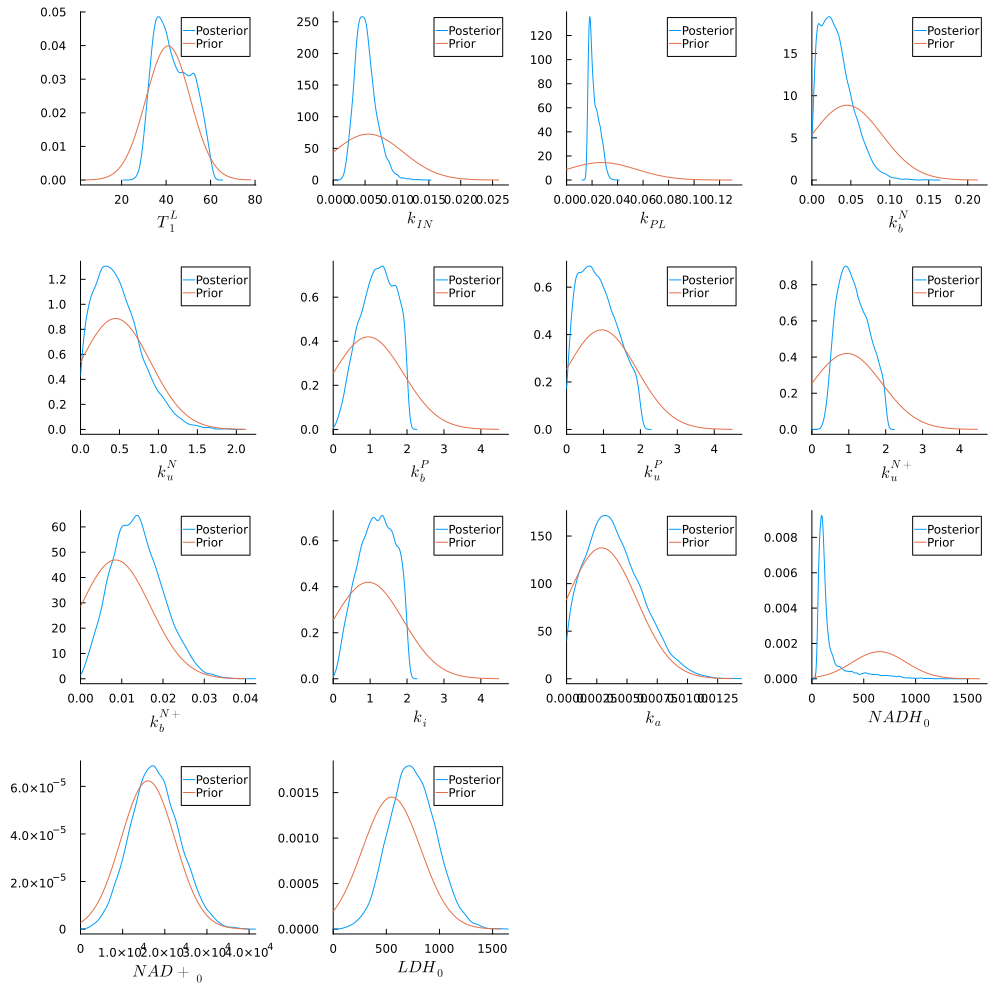

In [53]:
pp0 = plot(kde(poster[:,1]), label = "Posterior", xlabel = namess[1])
plot!(Normal(40.92, 10), label = "Prior")

pp1 = plot(kde(poster[:,3]), label = "Posterior", xlabel = namess[2])
plot!(Normal(0.0055, 0.0055), label = "Prior", xlim = (0, 0.0055+4*0.0055))

pp2 = plot(kde(poster[:,4]), label = "Posterior", xlabel = namess[3])
plot!(Normal(0.0275, 0.0275), label = "Prior", xlim = (0, 0.0275+4*0.0275))

pp3 = plot(kde(poster[:,5]), label = "Posterior", xlabel = namess[4])
plot!(Normal(0.045, 0.045), label = "Prior", xlim = (0, 0.045+4*0.045))

pp4 = plot(kde(poster[:,6]), label = "Posterior", xlabel = namess[5])
plot!(Normal(0.45, 0.45), label = "Prior", xlim = (0, 0.45+4*0.45))

pp5 = plot(kde(poster[:,7]), label = "Posterior", xlabel = namess[6])
plot!(Normal(0.95, 0.95), label = "Prior", xlim = (0, 0.95+4*0.95))

pp6 = plot(kde(poster[:,8]), label = "Posterior", xlabel = namess[7])
plot!(Normal(0.95, 0.95), label = "Prior", xlim = (0, 0.95+4*0.95))

pp7 = plot(kde(poster[:,9]), label = "Posterior", xlabel = namess[8])
plot!(Normal(0.95, 0.95), label = "Prior", xlim = (0, 0.95+4*0.95))

pp8 = plot(kde(poster[:,10]), label = "Posterior", xlabel = namess[9])
plot!(Normal(0.0085, 0.0085), label = "Prior", xlim = (0, 0.0085+4*0.0085))

pp9 = plot(kde(poster[:,11]), label = "Posterior", xlabel = namess[10])
plot!(Normal(0.95, 0.95), label = "Prior", xlim = (0, 0.95+4*0.95))

pp10 = plot(kde(poster[:,12]), label = "Posterior", xlabel = namess[11])
plot!(Normal(0.0029, 0.0029), label = "Prior", xlim = (0, 0.0029+4*0.0029))


pp11 = plot(kde(poster[:,14]), label = "Posterior", xlabel = namess[12])
plot!(Normal(650, 260), label = "Prior", xlim = (0, 650+4*260))

pp12 = plot(kde(poster[:,15]), label = "Posterior", xlabel = namess[13])
plot!(Normal(16000, 6400), label = "Prior", xlim = (0, 16000+4*6400))

pp13 = plot(kde(poster[:,16]), label = "Posterior", xlabel = namess[14])
plot!(Normal(550, 275), label = "Prior", xlim = (0, 550+4*275))

plot(pp0,pp1,pp2,pp3,pp4,pp5,pp6,pp7,pp8,pp9,pp10,pp11,pp12,pp13, size=(1000,1000), grid = false)

In [54]:
-log(det(cov(hcat(poster[:,1], poster[:,3:12], poster[:,14:end]))))

27.046124792184443

In [56]:
using CairoMakie
using PairPlots
using DataFrames

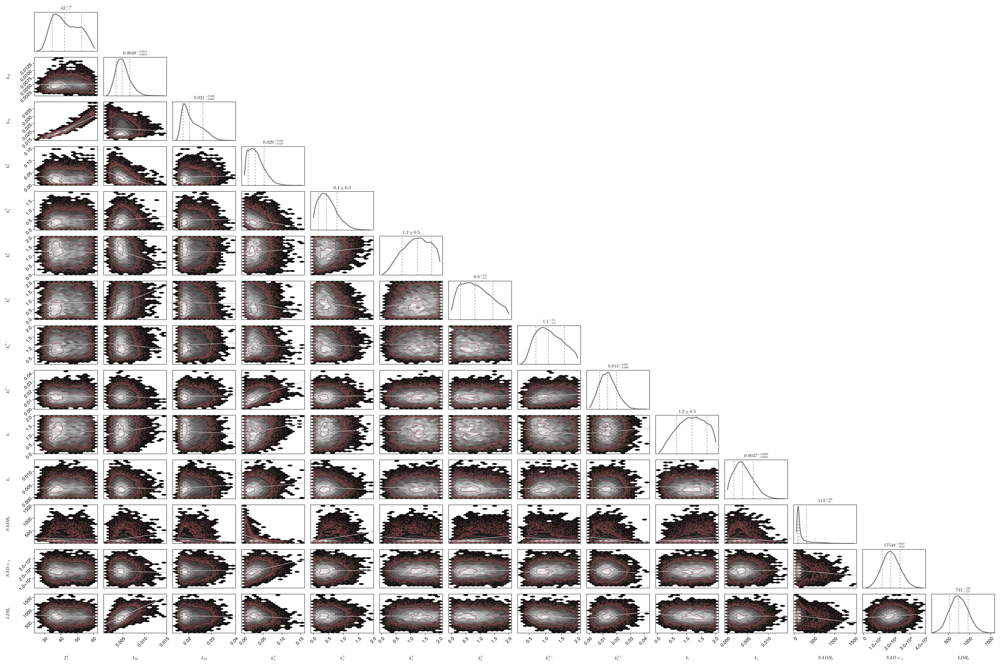

In [57]:
label = [L"T_1^L",L"k_{IN}",L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_a",L"NADH_0",L"NAD+_0",L"LDH_0"]

postCut = hcat(poster[:,1], poster[:,3:12], poster[:,14:end]);
df = DataFrame(postCut, :auto)

fig = Figure(size=(3000,2000))
# 
pairplot(fig[1,1], df => (
    PairPlots.HexBin(colormap=:grays, alpha=1), # RdYlGn
    PairPlots.Scatter(filtersigma=2, color="#884a4aff", markersize=3, alpha=0.65),
    PairPlots.Contour(color="#884a4aff", alpha=0.85),
    # # New:
    
    PairPlots.MarginConfidenceLimits(),
    PairPlots.MarginDensity(color="gray", linewidth=3),
    PairPlots.TrendLine(color="#c0b5b9ff"), # default is red
    
), 
labels = Dict(:x1 => label[1],:x2 => label[2],:x3 => label[3],:x4 => label[4],:x5 => label[5],:x6 => label[6],:x7 => label[7],:x8 => label[8],:x9 => label[9],:x10 => label[10],
              :x11 => label[11],:x12 => label[12],:x13 => label[13],:x14 => label[14]))

save("D:\\David\\BayesianInferencesInVivoScripts\\Figures\\SuppFig6Stuff\\PosteriorCovariance_ID2bExperiment.svg", fig)


fig

# Simulate Experiment Current Posterior

In [58]:
simsPoster = Array{Any}(undef, 8000, 3);

for j in 1:3
for i in 1:8000
    tsC2 = dat["sts"][:,j];
    ts = 0:tsC2[end];
    ivss = [dat["Means"][1,j,1]/(dat["ScFms"][j]*0.12), 0, 0, poster[i,14], poster[i,15], poster[i,16], 0, 0, 0, 0, 0, dat["Means"][1,j,1]/(dat["ScFms"][j]*0.12), 0, dat["Means"][1,j,1]];;
    samps = convert.(Int, tsC2);

    SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(poster[i,1:12], dat["ScFms"][j], 0), ivss, samps);

    simsPoster[i,j] = SimulsAll;
end
end

In [59]:
dat["ScFms"]

1×3 Matrix{Float64}:
 23.8997  21.2072  26.5331

### Experiment 1

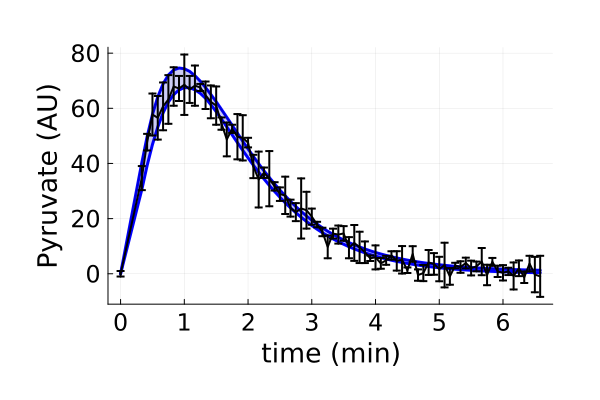

In [60]:
# Dims = Up/Down, Observable, Experiment
PostQuant = Array{Any}(undef,2,1,2);
lacPostSims = zeros(size(simsPoster[1,1])[1], 8000)
[lacPostSims[:,i] = simsPoster[i,1][:,13,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:2
        PostQuant[1,k,m] = [percentile(lacPostSims[j,:], 99.5) for j in 1:size(lacPostSims)[1]]; # Up
        PostQuant[2,k,m] = [percentile(lacPostSims[j,:], 0.5 ) for j in 1:size(lacPostSims)[1]]; # Down
    end
end

pr = plot(tsC2./60, PostQuant[1,1,1], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Pyruvate (AU)")
  plot!(tsC2./60, PostQuant[2,1,1], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PostQuant[1,1,1], fillrange=PostQuant[2,1,1], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,1]./60, dat["Means"][:,1,2], yerror = dat["Erros"][:,1,2], linewidth = 2, colour = "black", label = "")

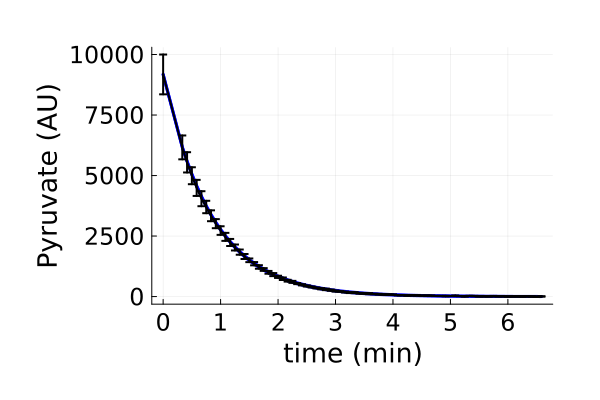

In [61]:
# Dims = Up/Down, Observable, Experiment
PostQuant = Array{Any}(undef,2,1,2);
pyrPostSims = zeros(size(simsPoster[1,1])[1], 8000)
[pyrPostSims[:,i] = simsPoster[i,1][:,14,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:2
        PostQuant[1,k,m] = [percentile(pyrPostSims[j,:], 99.5) for j in 1:size(pyrPostSims)[1]]; # Up
        PostQuant[2,k,m] = [percentile(pyrPostSims[j,:], 0.5 ) for j in 1:size(pyrPostSims)[1]]; # Down
    end
end

pr = plot(tsC2./60, PostQuant[1,1,1], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Pyruvate (AU)")
  plot!(tsC2./60, PostQuant[2,1,1], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PostQuant[1,1,1], fillrange=PostQuant[2,1,1], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,1]./60, dat["Means"][:,1,1], yerror = dat["Erros"][:,1,1], linewidth = 2, colour = "black", label = "")

## Experiment 2

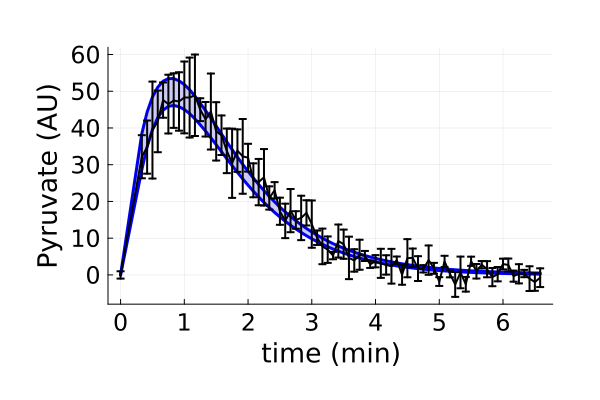

In [62]:
# Dims = Up/Down, Observable, Experiment
PostQuant = Array{Any}(undef,2,1,2);
lacPostSims = zeros(size(simsPoster[1,1])[1], 8000)
[lacPostSims[:,i] = simsPoster[i,2][:,13,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:2
        PostQuant[1,k,m] = [percentile(lacPostSims[j,:], 99.5) for j in 1:size(lacPostSims)[1]]; # Up
        PostQuant[2,k,m] = [percentile(lacPostSims[j,:], 0.5 ) for j in 1:size(lacPostSims)[1]]; # Down
    end
end

pr = plot(tsC2./60, PostQuant[1,1,2], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Pyruvate (AU)")
  plot!(tsC2./60, PostQuant[2,1,2], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PostQuant[1,1,2], fillrange=PostQuant[2,1,2], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,2]./60, dat["Means"][:,2,2], yerror = dat["Erros"][:,2,2], linewidth = 2, colour = "black", label = "")

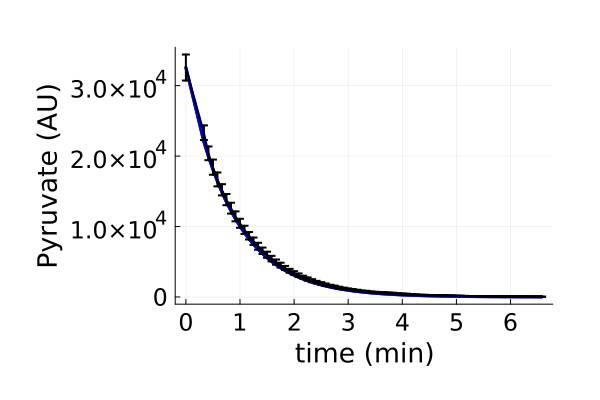

In [63]:
# Dims = Up/Down, Observable, Experiment
PostQuant = Array{Any}(undef,2,1,2);
pyrPostSims = zeros(size(simsPoster[1,1])[1], 8000)
[pyrPostSims[:,i] = simsPoster[i,2][:,14,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:2
        PostQuant[1,k,m] = [percentile(pyrPostSims[j,:], 99.5) for j in 1:size(pyrPostSims)[1]]; # Up
        PostQuant[2,k,m] = [percentile(pyrPostSims[j,:], 0.5 ) for j in 1:size(pyrPostSims)[1]]; # Down
    end
end

pr = plot(tsC2./60, PostQuant[1,1,2], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Pyruvate (AU)")
  plot!(tsC2./60, PostQuant[2,1,2], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PostQuant[1,1,2], fillrange=PostQuant[2,1,2], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,2]./60, dat["Means"][:,2,1], yerror = dat["Erros"][:,2,1], linewidth = 2, colour = "black", label = "")

## Experiment 3

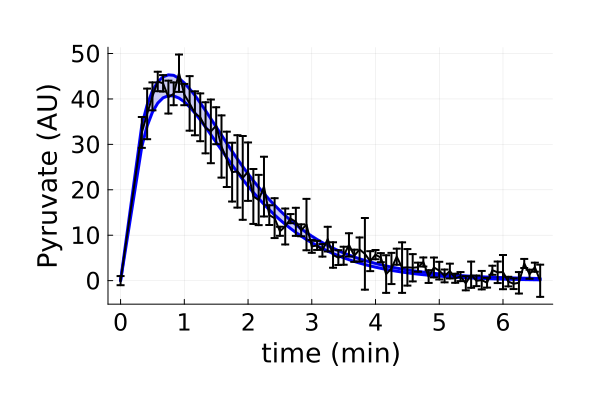

In [64]:
# Dims = Up/Down, Observable, Experiment
PostQuant = Array{Any}(undef,2,1,2);
lacPostSims = zeros(size(simsPoster[1,1])[1], 8000)
[lacPostSims[:,i] = simsPoster[i,3][:,13,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:2
        PostQuant[1,k,m] = [percentile(lacPostSims[j,:], 99.5) for j in 1:size(lacPostSims)[1]]; # Up
        PostQuant[2,k,m] = [percentile(lacPostSims[j,:], 0.5 ) for j in 1:size(lacPostSims)[1]]; # Down
    end
end

pr = plot(tsC2./60, PostQuant[1,1,2], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Pyruvate (AU)")
  plot!(tsC2./60, PostQuant[2,1,2], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PostQuant[1,1,2], fillrange=PostQuant[2,1,2], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,3]./60, dat["Means"][:,3,2], yerror = dat["Erros"][:,3,2], linewidth = 2, colour = "black", label = "")

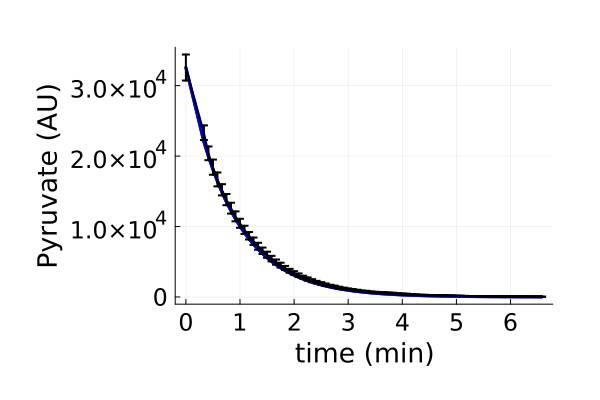

In [65]:
# Dims = Up/Down, Observable, Experiment
PostQuant = Array{Any}(undef,2,1,2);
pyrPostSims = zeros(size(simsPoster[1,1])[1], 8000)
[pyrPostSims[:,i] = simsPoster[i,2][:,14,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:2
        PostQuant[1,k,m] = [percentile(pyrPostSims[j,:], 99.5) for j in 1:size(pyrPostSims)[1]]; # Up
        PostQuant[2,k,m] = [percentile(pyrPostSims[j,:], 0.5 ) for j in 1:size(pyrPostSims)[1]]; # Down
    end
end

pr = plot(tsC2./60, PostQuant[1,1,2], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Pyruvate (AU)")
  plot!(tsC2./60, PostQuant[2,1,2], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PostQuant[1,1,2], fillrange=PostQuant[2,1,2], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,2]./60, dat["Means"][:,2,1], yerror = dat["Erros"][:,2,1], linewidth = 2, colour = "black", label = "")